In [20]:
import numpy as np
import pandas as pd

In [21]:
df = pd.read_csv('titanic.csv')

In [22]:
df.head()

,Cabin,Ticket,number,Survived
0,NaN,A/5 21171,5,0
1,C85,PC 17599,3,1
2,NaN,STON/O2. 3101282,6,1
3,C123,113803,3,1
4,NaN,373450,A,0


In [23]:
df['number'].unique()

<ArrowStringArray>
['5', '3', '6', 'A', '2', '1', '4']
Length: 7, dtype: str

Text(0.5, 1.0, 'Passengers travelling with')

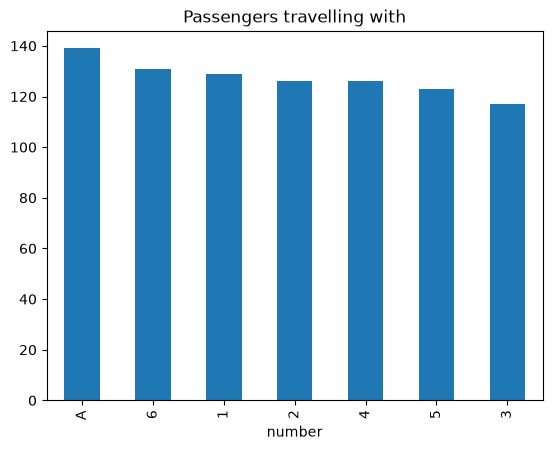

In [24]:
fig = df['number'].value_counts().plot.bar()
fig.set_title('Passengers travelling with')

In [25]:
# extract numerical part

df['number_numerical'] = pd.to_numeric(df["number"], errors='coerce', downcast='integer')

In [30]:
# extract categorical part

# np.where(condition, value_if_true, value_if_false)

df['number_categorical'] = np.where(df['number_numerical'].isnull(),df['number'],np.nan)

In [31]:
df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical
0,NaN,A/5 21171,5,0,5.0,NaN
1,C85,PC 17599,3,1,3.0,NaN
2,NaN,STON/O2. 3101282,6,1,6.0,NaN
3,C123,113803,3,1,3.0,NaN
4,NaN,373450,A,0,NaN,A


In [32]:
df['Cabin'].unique()

<ArrowStringArray>
[          nan,         'C85',        'C123',         'E46',          'G6',
        'C103',         'D56',          'A6', 'C23 C25 C27',         'B78',
 ...
        'B102',         'B69',         'E49',         'C47',         'D28',
         'E17',         'A24',         'C50',         'B42',        'C148']
Length: 148, dtype: str

In [33]:
df['Ticket'].unique()

<ArrowStringArray>
[       'A/5 21171',         'PC 17599', 'STON/O2. 3101282',
           '113803',           '373450',           '330877',
            '17463',           '349909',           '347742',
           '237736',
 ...
           '349212',           '349217',           '349257',
             '7552', 'C.A./SOTON 34068',  'SOTON/OQ 392076',
           '211536',           '112053',           '111369',
           '370376']
Length: 681, dtype: str

Text(0.5, 1.0, 'Passengers travelling with')

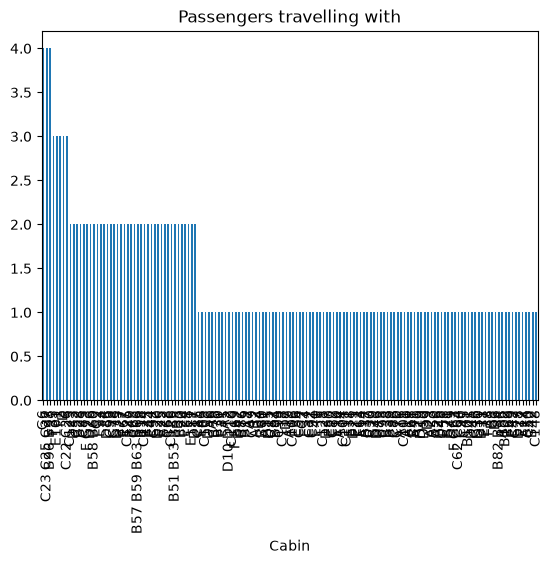

In [36]:
fig = df['Cabin'].value_counts().plot.bar()
fig.set_title('Passengers travelling with')

In the number column: Different rows have completely different types of data. For example, Row 0 has a number (5), but Row 4 has a letter (A). Because they are mixed up across different rows, we had to use np.where to sort them into two separate columns.   In the Cabin column: Every single value (like C85 or C123) already has both a letter and a number smashed together inside the exact same box.   Because a single cabin code contains both pieces at once, we don't need to sort rows. Instead, we use code to slice and extract both parts out of that single string!

In [34]:
# now we extract data for cabin

df['cabin_num'] = df['Cabin'].str.extract('(\d+)') # captures numerical part
df['cabin_cat'] = df['Cabin'].str[0] # captures the first Lettter

df.head()

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,cabin_num,cabin_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN
1,C85,PC 17599,3,1,3.0,NaN,85,C
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN
3,C123,113803,3,1,3.0,NaN,123,C
4,NaN,373450,A,0,NaN,A,NaN,NaN


In [38]:
df['cabin_cat'].value_counts()

cabin_cat
C    59
B    47
D    33
E    32
A    15
F    13
G     4
T     1
Name: count, dtype: int64

<Axes: xlabel='cabin_cat'>

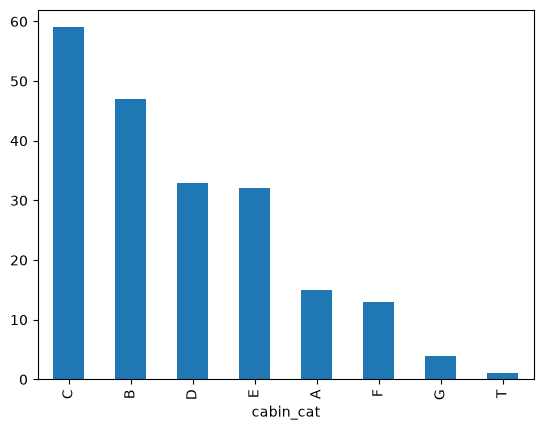

In [39]:
df['cabin_cat'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'Passengers travelling with')

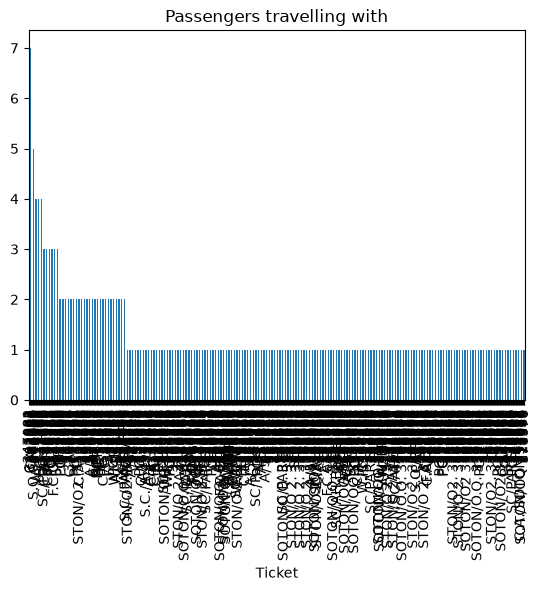

In [40]:
fig = df['Ticket'].value_counts().plot.bar()
fig.set_title('Passengers travelling with')

lambda s: creates a quick mini-function that looks at every individual row's text one by one and names it s.

s.split() cuts the text wherever there is a space.

For a ticket with letters and numbers (e.g., "A/5 21171"):

s.split() cuts it into two pieces: ['A/5', '21171']

[-1] grabs the last piece: "21171" (used for the number column)

[0] grabs the first piece: "A/5" (used for the category column)

For a ticket with only numbers (e.g., "113803"):

s.split() leaves it as a single piece: ['113803']

[-1] grabs it: "113803" (treated as the number)

[0] also grabs it: "113803" (which the next line of code deletes and turns into NaN because it's a number, not text)

In [43]:
# extract the last bit of ticket as number
df['ticket_num'] = df['Ticket'].apply(lambda s : s.split()[-1])
df['ticket_num'] = pd.to_numeric(df['ticket_num'],
                                errors = 'coerce',
                                downcast= 'integer')

# extract the first par of the tickrt as category

# np.where(condition, value_if_true, value_if_false)

df['ticket_cat'] = df['Ticket'].apply(lambda s : s.split()[0])
df['ticket_cat'] = np.where(df['ticket_cat'].str.isdigit(),
                           np.nan,
                           df['ticket_cat'])

In [44]:
df.head(20)

,Cabin,Ticket,number,Survived,number_numerical,number_categorical,cabin_num,cabin_cat,ticket_num,ticket_cat
0,NaN,A/5 21171,5,0,5.0,NaN,NaN,NaN,21171.0,A/5
1,C85,PC 17599,3,1,3.0,NaN,85,C,17599.0,PC
2,NaN,STON/O2. 3101282,6,1,6.0,NaN,NaN,NaN,3101282.0,STON/O2.
3,C123,113803,3,1,3.0,NaN,123,C,113803.0,NaN
4,NaN,373450,A,0,NaN,A,NaN,NaN,373450.0,NaN
5,NaN,330877,2,0,2.0,NaN,NaN,NaN,330877.0,NaN
6,E46,17463,2,0,2.0,NaN,46,E,17463.0,NaN
7,NaN,349909,5,0,5.0,NaN,NaN,NaN,349909.0,NaN
8,NaN,347742,1,1,1.0,NaN,NaN,NaN,347742.0,NaN
9,NaN,237736,A,1,NaN,A,NaN,NaN,237736.0,NaN
